### 1. Ініціалізація та швидке зчитування даних
Підключення графічних бібліотек (Matplotlib, Seaborn), налаштування стилю та швидке завантаження очищеного набору з файлу `flights_clean.parquet`.

In [1]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

os.makedirs("../report/figures", exist_ok=True)

df = pd.read_parquet("flights_clean.parquet")
print(f"Дані завантажено: {df.shape[0]} рядків, {df.shape[1]} колонок.")

Дані завантажено: 5714008 рядків, 9 колонок.


### 2. Розвідувальний аналіз даних (EDA) та збереження графіків
- Аналіз дисбалансу класів цільової змінної `is_delayed`.
- Дослідження залежності частки затримок від години доби.
- Порівняння частоти затримок за авіаперевізниками.
- Експорт графіків у папку `report/figures/` для звіту та презентації.

C:\Users\vadim\AppData\Local\Temp\ipykernel_16404\3839662490.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x="is_delayed", data=df, palette="Blues_r")


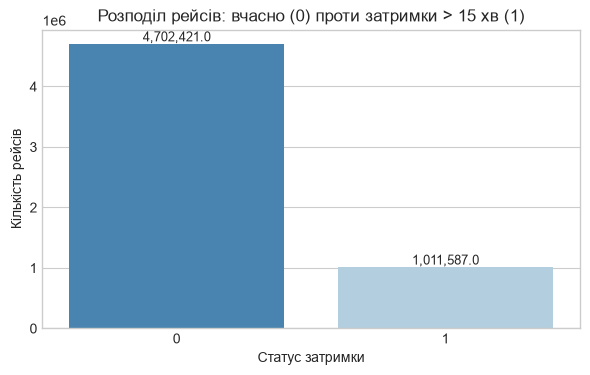

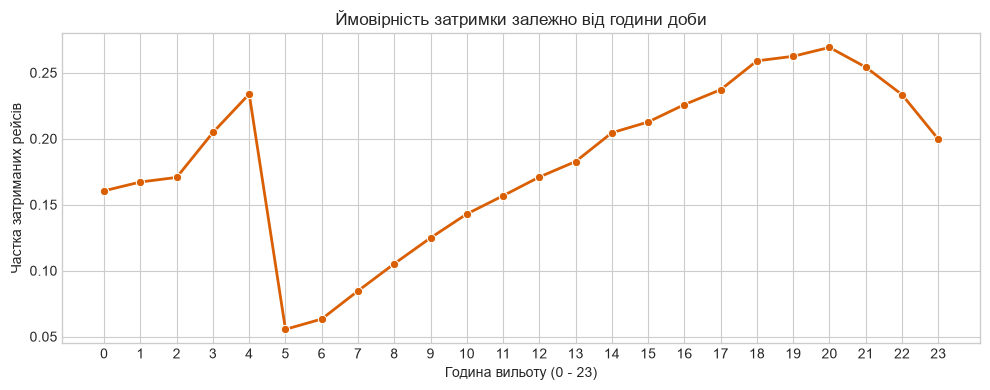

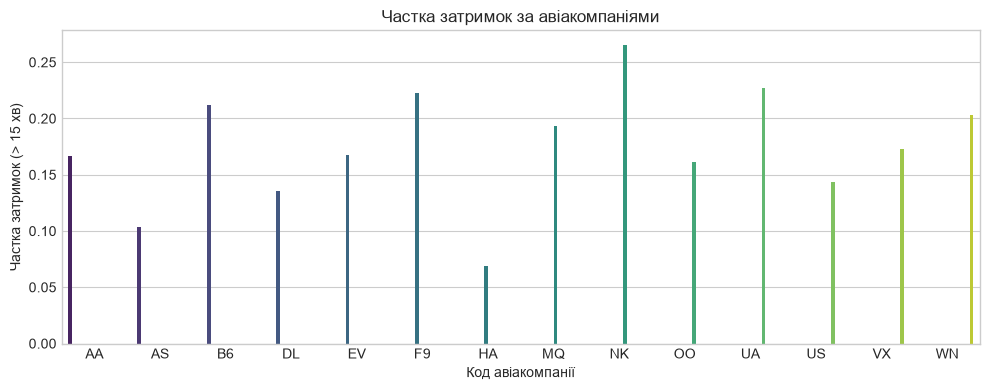

In [3]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(x="is_delayed", data=df, palette="Blues_r")
plt.title("Розподіл рейсів: вчасно (0) проти затримки > 15 хв (1)")
plt.xlabel("Статус затримки")
plt.ylabel("Кількість рейсів")
for p in ax.patches:
    ax.annotate(
        f"{p.get_height():,}",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="bottom",
        fontsize=9,
    )
plt.tight_layout()
plt.savefig("../report/figures/target_distribution.png", dpi=200)
plt.show()

hourly_delay = df.groupby("dep_hour")["is_delayed"].mean().reset_index()

plt.figure(figsize=(10, 4))
sns.lineplot(
    data=hourly_delay,
    x="dep_hour",
    y="is_delayed",
    marker="o",
    color="#d95f02",
    linewidth=2,
)
plt.title("Ймовірність затримки залежно від години доби")
plt.xlabel("Година вильоту (0 - 23)")
plt.ylabel("Частка затриманих рейсів")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.savefig("../report/figures/delay_by_hour.png", dpi=200)
plt.show()

airline_stats = (
    df.groupby("AIRLINE")["is_delayed"]
    .agg(["mean", "count"])
    .reset_index()
    .rename(columns={"mean": "delay_rate", "count": "total_flights"})
)
airline_stats = airline_stats.sort_values(
    by="delay_rate", ascending=False
).reset_index(drop=True)

plt.figure(figsize=(10, 4))
sns.barplot(
    data=airline_stats,
    x="AIRLINE",
    y="delay_rate",
    palette="viridis",
    hue="AIRLINE",
    legend=False,
)
plt.title("Частка затримок за авіакомпаніями")
plt.xlabel("Код авіакомпанії")
plt.ylabel("Частка затримок (> 15 хв)")
plt.tight_layout()
plt.savefig("../report/figures/delay_by_airline.png", dpi=200)
plt.show()